# MSCS 634 - Lab 2: KNN and Radius Neighbors on the Wine Dataset
**Name:** Umama Azhar
**Course:** MSCS 634 
**Lab:** Lab 2 - K-Nearest Neighbors and Radius Neighbors Classifiers

In [2]:
#numpy handles arrays of numbers.
#pandas gives us tables (DataFrames).
#load_wine fetches the built-in dataset.
#train_test_split divides the data.
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split


In [3]:
#wine is a bundle holding everything about the dataset. We pull out two pieces:
#X is the features: 13 chemical measurements per wine (alcohol, proline, color intensity, and so on). These are the model's inputs.
#y is the target: which of the 3 wine classes each wine belongs to (0, 1, or 2). This is the answer we want the model to predict.

wine = load_wine()
X, y = wine.data, wine.target


In [5]:
#X.shape gives (rows, columns), meaning how many wines and how many features.
#feature_names lists what each column measures.
#target_names gives the class names.
#np.bincount(y) counts how many wines are in each class. This checks whether the classes are balanced. If one class had 170 wines and the others had
#4 each, accuracy would be misleading, because a model could just always guess the big class

print("Shape:", X.shape)
print("Features:", wine.feature_names)
print("Classes:", wine.target_names)
print("Class counts:", np.bincount(y))

Shape: (178, 13)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes: ['class_0' 'class_1' 'class_2']
Class counts: [59 71 48]


In [6]:
#describe() computes count, mean, standard deviation, min, max, and so on.
#.T flips the table so each feature is a row, which is easier to read.
#[["mean","std","min","max"]] keeps only the columns we care about.

df = pd.DataFrame(X, columns=wine.feature_names)
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


**Step 2: K-Nearest Neighbors (KNN)**

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

#test_size=0.2 means 20% goes to testing and 80% to training.
#random_state=42 fixes the shuffle. Without it, the split changes every run and accuracy numbers would shift each time. 
#The four outputs are the training inputs and answers (X_train, y_train) and the testing inputs and answers (X_test, y_test)

Train: (142, 13) Test: (36, 13)


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Train:", X_train.shape, "Test:", X_test.shape)

k_values = [1, 5, 11, 15, 21]
knn_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    knn_accuracies.append(acc)
    print(f"k = {k:2d}  ->  accuracy = {acc:.4f}")


#KNeighborsClassifier(n_neighbors=k) creates the model and tells it how many neighbors get a vote.
#.fit(X_train, y_train) "trains" it. KNN doesn't learn a formula. It just stores the training wines so it can look them up later.
#.predict(X_test) takes each of the 36 test wines, finds its k nearest training wines, and returns the voted class for each.
#accuracy_score(y_test, y_pred) compares the predictions to the true answers. The result is the fraction correct. For example, 0.75 means 27 of 36 right.
#The for loop repeats all of this for each k, so we can compare them. We save each result in knn_accuracies, because Step 4 needs that list for the plot.

Train: (142, 13) Test: (36, 13)
k =  1  ->  accuracy = 0.7778
k =  5  ->  accuracy = 0.7222
k = 11  ->  accuracy = 0.7500
k = 15  ->  accuracy = 0.7500
k = 21  ->  accuracy = 0.7778


In [ ]:
#What the pattern shows
#The trend is a small dip, then a recovery. Accuracy starts at 0.7778, falls to 0.7222 at k = 5, and climbs back to 0.7778 at k = 21. 
#It does not rise or fall steadily.The differences are tiny. With only 36 test wines, one wine is worth about 2.8 percentage points.
#A gap between k = 5 and k = 21 could easily change with a different random split. So don't claim that one k is truly better.
#A safer conclusion is that k has only a small effect here.
#All the numbers are moderate (about 72 to 78%). 
#The model is mostly comparing wines by proline (and a bit by magnesium), and those two features don't separate the three classes cleanly.

In [10]:
print(knn_accuracies)

[0.7777777777777778, 0.7222222222222222, 0.75, 0.75, 0.7777777777777778]


**Step 3: Radius Neighbors**

In [11]:
from sklearn.neighbors import RadiusNeighborsClassifier

radius_values = [350, 400, 450, 500, 550, 600]
rnn_accuracies = []

for r in radius_values:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent")
    rnn.fit(X_train, y_train)
    y_pred = rnn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    rnn_accuracies.append(acc)
    print(f"radius = {r}  ->  accuracy = {acc:.4f}")

print(rnn_accuracies)

# RadiusNeighborsClassifier(radius=r) creates the model. Every training wine within distance r of a test wine gets a vote.
# Unlike KNN, the number of voters changes from wine to wine: crowded areas give many voters, sparse areas give few.
# outlier_label="most_frequent" is a safety net. If no training wine falls inside the circle, the model guesses the most common training class instead of crashing.
# .fit and .predict work like in KNN. Fit stores the training wines, and predict draws the circle around each test wine and takes the vote.
# rnn_accuracies saves the six results, because Step 4 needs this list for the plot, just like knn_accuracies.

radius = 350  ->  accuracy = 0.7500
radius = 400  ->  accuracy = 0.7222
radius = 450  ->  accuracy = 0.7222
radius = 500  ->  accuracy = 0.7222
radius = 550  ->  accuracy = 0.7222
radius = 600  ->  accuracy = 0.7222
[0.75, 0.7222222222222222, 0.7222222222222222, 0.7222222222222222, 0.7222222222222222, 0.7222222222222222]


In [ ]:
# RNN Results and Interpretation
#Accuracy was 0.7500 (27/36) at radius 350 and 0.7222 (26/36) for every radius from 400 to 600.
#Increasing the radius beyond 400 did not change any predictions on the test set. Only one wine differed between radius 350 and the larger radii.
#One likely reason is that distances are dominated by `proline` on the unscaled data, so larger circles keep adding more of the same neighbors.
#I did not verify this.Overall accuracy is moderate for the same reason as KNN: unscaled features.

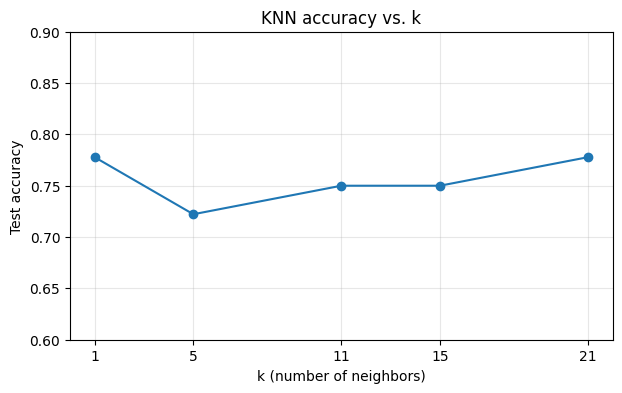

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_accuracies, marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Test accuracy")
plt.title("KNN accuracy vs. k")
plt.xticks(k_values)
plt.ylim(0.6, 0.9)
plt.grid(True, alpha=0.3)
plt.show()

#matplotlib.pyplot is Python's standard plotting library.
#plt.plot(k_values, knn_accuracies, marker="o") draws a line with k on the horizontal axis and accuracy on the vertical axis. The marker="o" puts a dot at each of your five results.
#plt.xlabel, plt.ylabel, and plt.title label the chart. Graders look for these.
#plt.xticks(k_values) puts tick marks at exactly 1, 5, 11, 15, and 21, so the axis shows the k values you tested.
#plt.ylim(0.6, 0.9) fixes the vertical range. Without it, matplotlib zooms in tightly and a 2-wine difference can look like a huge swing. A wider range keeps the picture honest.
#plt.grid adds light gridlines, and plt.show() displays the chart.

In [ ]:
# KNN Accuracy Trend
#The plot shows accuracy of 0.7778 at k = 1, a dip to 0.7222 at k = 5, 0.75 at k = 11 and k = 15, and a return to 0.7778 at k = 21. 
#There is no steady upward or downward trend. The total spread is 2 wines out of 36, so k had only a small effect on this test set.

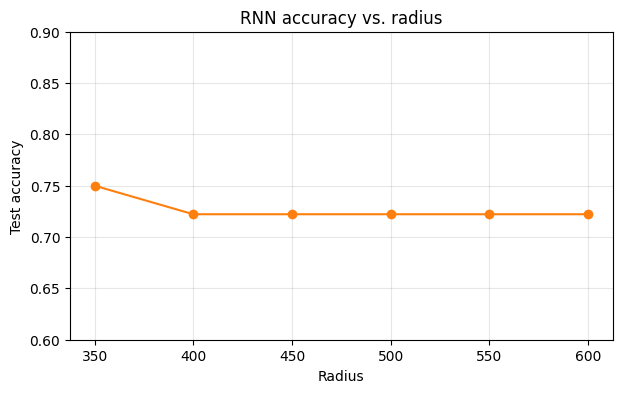

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(radius_values, rnn_accuracies, marker="o", color="tab:orange")
plt.xlabel("Radius")
plt.ylabel("Test accuracy")
plt.title("RNN accuracy vs. radius")
plt.xticks(radius_values)
plt.ylim(0.6, 0.9)
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
#RNN Accuracy Trend
#The plot shows accuracy of 0.7500 at radius 350, dropping to 0.7222 at radius 400 and staying there through radius 600. 
#Increasing the radius past 400 did not change any predictions on the test set.The only difference across the whole range is one wine.

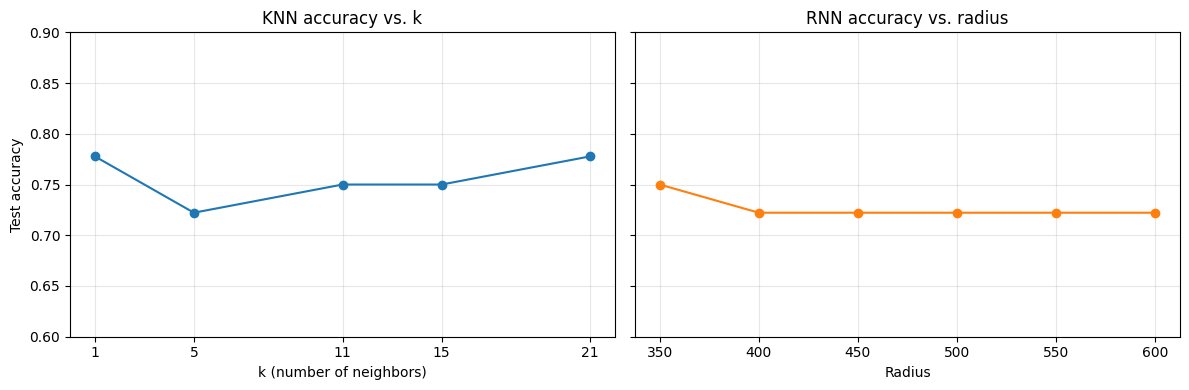

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].plot(k_values, knn_accuracies, marker="o")
axes[0].set_title("KNN accuracy vs. k")
axes[0].set_xlabel("k (number of neighbors)")
axes[0].set_ylabel("Test accuracy")
axes[0].set_xticks(k_values)
axes[0].grid(True, alpha=0.3)

axes[1].plot(radius_values, rnn_accuracies, marker="o", color="tab:orange")
axes[1].set_title("RNN accuracy vs. radius")
axes[1].set_xlabel("Radius")
axes[1].set_xticks(radius_values)
axes[1].grid(True, alpha=0.3)

axes[0].set_ylim(0.6, 0.9)
plt.tight_layout()
plt.show()

#plt.subplots(1, 2, ...) creates one row with two chart panels. axes[0] is the left panel and axes[1] is the right.
#sharey=True makes both panels use the same vertical scale. That is what makes the comparison fair, because a dot at 0.75 sits at the same height in both.
#The axes[0].plot(...) and axes[1].plot(...) blocks draw your KNN and RNN results, one per panel, with their own titles and labels.
#axes[0].set_ylim(0.6, 0.9) sets the shared range. Because the axis is shared, this one line applies to both panels.
#plt.tight_layout() stops the labels from overlapping.

In [ ]:
# Comparison of KNN and RNN

#Best accuracy was 0.7778 (28/36) for KNN (k = 1 and k = 21) and 0.7500 (27/36) for RNN (radius = 350).
#That is a one-wine difference, too small to call either model better with only 36 test wines.
#KNN accuracy varied slightly with k (0.7222 to 0.7778). 
#RNN accuracy was flat at 0.7222 from radius 400 to 600, so changing the radius had almost no effect once it was large enough.
#Both models scored in the 72-78% range. 
#Both use distance, and the features are unscaled, so `proline` dominates the distance and the other features contribute little.

### When to Prefer KNN or RNN

#KNN is a good default. Every test point gets a fixed number of voters, even in sparse regions, and k does not depend on the scale of the features.
#RNN fits when a fixed distance has real meaning and neighborhoods should vary in size, for example dense clusters with occasional outliers.
#It also shows which points have no close neighbors. Its weakness is that the radius must be matched to the scale of the data. 
#My radii only worked because raw distances here are in the hundreds.
#On this dataset, the results do not favor either model.
#If I had to choose, I would pick KNN for its simpler tuning, and I would scale the features before using either model.